# UTS Graf Sains Data: RetailRocket + Neo4j

### Persiapan dan perkenalan lingkungan

In [2]:
# 1.1 requirements + cek environment
REQ = """neo4j>=5.0
pandas
tqdm
networkx
scipy
scikit-learn
matplotlib
"""
open("requirements.txt", "w").write(REQ)

import sys, neo4j
print("Python :", sys.version.split()[0])
print("venv   :", sys.executable)
print("neo4j  :", neo4j.__version__)
assert int(neo4j.__version__.split(".")[0]) >= 5, "Driver neo4j < 5: jalankan  pip install -U 'neo4j>=5'"

Python : 3.13.15
venv   : c:\Users\Asus\Downloads\UTS GRAF\myenv\Scripts\python.exe
neo4j  : 6.4.1


In [ ]:
# Setup
import os, math, time, argparse, subprocess, zipfile
import numpy as np, pandas as pd, scipy.sparse as sp
import networkx as nx, matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from tqdm.auto import tqdm
from neo4j import GraphDatabase, RoutingControl
from neo4j.exceptions import DriverError, TransientError

DATA_DIR = "data"
URI, AUTH, DB = "neo4j://127.0.0.1:7687", ("neo4j", os.getenv("NEO4J_PASSWORD", "Hanamaftuha27")), "neo4j"
SEED = 42

P1 = ("2015-06-16", "2015-07-01")   
P2 = ("2015-09-01", "2015-09-19")   
W = {"VIEWED": 1.0, "ADDED_TO_CART": 3.0, "BOUGHT": 5.0}   

os.makedirs(DATA_DIR, exist_ok=True)

_driver = None

def get_driver():
    global _driver
    if _driver is None:
        _driver = GraphDatabase.driver(
            URI, auth=AUTH,
            max_connection_lifetime=180,          
            keep_alive=True,
            connection_acquisition_timeout=60,
        )
    return _driver

def reset_driver():
    global _driver
    try:
        if _driver is not None:
            _driver.close()
    except Exception:
        pass
    _driver = None

def with_retry(fn, tries=4):
    """Jalankan fn(); jika koneksi putus/driver tertutup, buat driver baru lalu coba lagi."""
    for k in range(tries):
        try:
            return fn()
        except (DriverError, TransientError) as e:
            if k == tries - 1:
                raise
            print(f"[koneksi bermasalah: {type(e).__name__}] mencoba lagi ({k + 1}/{tries - 1})...")
            reset_driver()
            time.sleep(2 * (k + 1))

def run(cypher, **params):
    """Jalankan Cypher, kembalikan list of dict (dengan retry)."""
    def _do():
        with get_driver().session(database=DB) as s:
            return s.run(cypher, **params).data()
    return with_retry(_do)

def df_q(cypher, **params):
    return pd.DataFrame(run(cypher, **params))

get_driver().verify_connectivity()
print("Terhubung ke Neo4j!")

c:\Users\Asus\Downloads\UTS GRAF\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Terhubung ke Neo4j!


### Mempelajari penggunaan driver Neo4j

Guinevere
Lancelot
Merlin


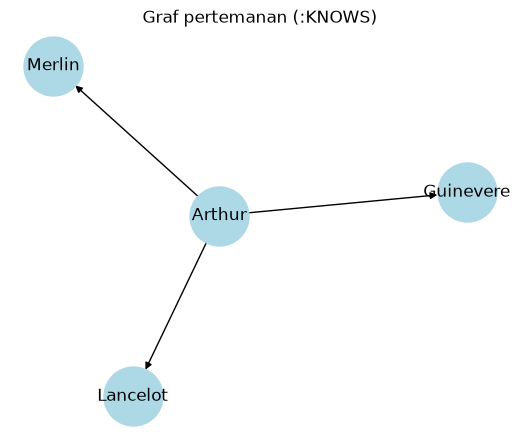

Database pada instance ini: ['neo4j', 'system']


In [ ]:
# 1.2 tutorial driver
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=DB,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.verify_connectivity()
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

    recs, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(b:Person) RETURN a.name AS a, b.name AS b", database_=DB)
    G = nx.DiGraph([(r["a"], r["b"]) for r in recs])
    plt.figure(figsize=(5, 4))
    nx.draw(G, nx.spring_layout(G, seed=SEED), with_labels=True, node_color="lightblue",
            node_size=1800, arrows=True)
    plt.title("Graf pertemanan (:KNOWS)")
    plt.show()

    dbs, _, _ = driver.execute_query("SHOW DATABASES", database_="system")
    print("Database pada instance ini:", [r["name"] for r in dbs])

In [ ]:
# CYPHER Total Reset
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    driver.execute_query("MATCH (n) DETACH DELETE n", database_=DB)
print("Database dikosongkan.")

Database dikosongkan.


### Impor data RetailRocket ke Neo4j

In [ ]:
# 1.3 langkah 1: unduh data 
ZIP = "ecommerce-dataset.zip"
EVENTS_CSV = f"{DATA_DIR}/events.csv"
if not os.path.exists(EVENTS_CSV):
    URL = "https://www.kaggle.com/api/v1/datasets/download/retailrocket/ecommerce-dataset"
    subprocess.run(["curl", "-L", "-o", ZIP, URL], check=True)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(DATA_DIR)
    print("Data diunduh dan diekstrak.")
else:
    print("events.csv sudah ada, unduh dilewati.")

events.csv sudah ada, unduh dilewati.


## Wrangling dan EDA
### Filter 2 periode pada timestamp, simpan ke CSV (persiapan data sebelum impor)


In [7]:
# No. 1-2
events = pd.read_csv(EVENTS_CSV)
events["dt"] = pd.to_datetime(events["timestamp"], unit="ms")
print("Rentang data asli:", events["dt"].min(), "->", events["dt"].max())
print("Total baris:", len(events))

def filter_period(df, period):
    start, end = pd.Timestamp(period[0]), pd.Timestamp(period[1])
    return df[(df["dt"] >= start) & (df["dt"] < end)].drop(columns="dt")

p1 = filter_period(events, P1)
p2 = filter_period(events, P2)

P1_CSV = f"{DATA_DIR}/events_p1.csv"
P2_CSV = f"{DATA_DIR}/events_p2.csv"
p1.to_csv(P1_CSV, index=False)
p2.to_csv(P2_CSV, index=False)

ringkasan = pd.DataFrame({
    "periode": ["P1 (training)", "P2 (testing)"],
    "rentang (UTC)": [f"{P1[0]} s/d < {P1[1]}", f"{P2[0]} s/d < {P2[1]}"],
    "baris": [len(p1), len(p2)],
    "visitor unik": [p1.visitorid.nunique(), p2.visitorid.nunique()],
    "item unik": [p1.itemid.nunique(), p2.itemid.nunique()],
    "file": [P1_CSV, P2_CSV],
})
display(ringkasan)
display(pd.crosstab(["P1"] * len(p1), p1["event"]))
display(pd.crosstab(["P2"] * len(p2), p2["event"]))
del events

Rentang data asli: 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
Total baris: 2756101


,periode,rentang (UTC),baris,visitor unik,item unik,file
0,P1 (training),2015-06-16 s/d < 2015-07-01,309830,161249,81034,data/events_p1.csv
1,P2 (testing),2015-09-01 s/d < 2015-09-19,303710,173728,82220,data/events_p2.csv


event,addtocart,transaction,view
row_0,,,
P1,7985,2712,299133


event,addtocart,transaction,view
row_0,,,
P2,7681,2369,293660


### Session Neo4j, impor batch, query CYPHER impor

In [ ]:
# 1.3 langkah 3: argparse
def parse_arguments(argv=None):
    parser = argparse.ArgumentParser(
        description="Impor dataset RetailRocket (events.csv) ke database Neo4J."
    )
    parser.add_argument("-u", "--user", default=AUTH[0], help="Username Neo4j (default: neo4j)")
    parser.add_argument("-p", "--password", default=AUTH[1], help="Password Neo4J")
    parser.add_argument("-b", "--bolt", default=URI, help=f"Neo4J URI / Bolt (default: {URI})")
    parser.add_argument("-s", "--source", default=DATA_DIR, help="Direktori/folder sumber data (default: data)")
    parser.add_argument("-f", "--file", default="events_p1.csv", help="Berkas CSV hasil filter (default: events_p1.csv)")
    return parser.parse_args(argv)

args = parse_arguments([])   
print(args)

Namespace(user='neo4j', password='Hanamaftuha27', bolt='neo4j://127.0.0.1:7687', source='data', file='events_p1.csv')


In [ ]:
# 1.3 langkah 5: query CYPHER impor
USE_UNION = True   

def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    if USE_UNION:
        cypher_query = """
        UNWIND $batch AS row
        MERGE (v:Visitor {visitorId: row.visitorid})
        MERGE (i:Item {itemId: row.itemid})

        WITH v, i, row
        CALL {
            WITH v, i, row
            WITH v, i, row WHERE row.event = 'view'
            CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

            UNION ALL

            WITH v, i, row
            WITH v, i, row WHERE row.event = 'addtocart'
            CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

            UNION ALL

            WITH v, i, row
            WITH v, i, row WHERE row.event = 'transaction'
            CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
        }
        """
        tx.run(cypher_query, batch=batch)
    else:
        rel = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
        for ev, r in rel.items():
            rows_ev = [x for x in batch if x["event"] == ev]
            if not rows_ev:
                continue
            extra = ", transactionId: row.transactionid" if ev == "transaction" else ""
            tx.run(
                f"""UNWIND $rows AS row
                MERGE (v:Visitor {{visitorId: row.visitorid}})
                MERGE (i:Item {{itemId: row.itemid}})
                CREATE (v)-[:{r} {{timestamp: row.timestamp{extra}}}]->(i)""",
                rows=rows_ev,
            )

In [ ]:
# 1.3 langkah 3-4: cek berkas, koneksi, impor batch
csv_file_path = os.path.join(args.source, args.file)

if not os.path.exists(csv_file_path):
    raise SystemExit(f"Error: File '{csv_file_path}' tidak ditemukan!")

try:
    driver = get_driver()
    driver.verify_connectivity()
    print("Terhubung ke Neo4j!")
except Exception as e:
    raise SystemExit(f"Gagal terhubung ke database: {e}")

batch_size = 2000     
RELOAD = True         

def to_records(chunk):
    chunk = chunk.copy()
    # Membersihkan data null/NaN pada transactionid
    chunk["transactionid"] = chunk["transactionid"].apply(lambda x: "" if pd.isna(x) else str(int(x)))
    recs = chunk.to_dict(orient="records")
    return [{k: (v.item() if hasattr(v, "item") else v) for k, v in r.items()} for r in recs]

def write_batch(records):
    """Satu batch = satu transaksi di sesi baru. Aman diulang karena transaksi bersifat atomik."""
    global USE_UNION
    def _do():
        with get_driver().session(database=DB) as session:
            try:
                session.execute_write(import_batch, records)
            except Exception as e:
                if USE_UNION and not isinstance(e, (DriverError, TransientError)):
                    print("CALL..UNION ALL ditolak, pakai query ekuivalen. Detail:", str(e)[:120])
                    USE_UNION = False
                    session.execute_write(import_batch, records)
                else:
                    raise
    with_retry(_do)

if RELOAD:
    with get_driver().session(database=DB) as session:
        session.run("MATCH (n) DETACH DELETE n")
        create_constraints(session)

    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    total_rows = len(p1)
    total_chunks = (total_rows // batch_size) + 1

    print("Memulai proses impor data ke Neo4j...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        write_batch(to_records(chunk))
    print("Proses impor berhasil.")
else:
    print("RELOAD=False, impor dilewati.")

Terhubung ke Neo4j!
Membaca file data dari: data\events_p1.csv
Memulai proses impor data ke Neo4j...


Mengimpor Batch Data: 100%|██████████| 155/155 [01:01<00:00,  2.52it/s]

Proses impor berhasil.


In [ ]:
# Cek koneksi untuk analisis
driver = get_driver()
driver.verify_connectivity()
print("Terhubung ke Neo4j!")
display(df_q("MATCH (n) RETURN labels(n)[0] AS label, count(n) AS jumlah"))

Terhubung ke Neo4j!


,label,jumlah
0,Visitor,161249
1,Item,81034


### Komposisi subgraph (jenis simpul dan jumlahnya) via Python API

In [ ]:
# No. 3
komposisi_node = df_q("MATCH (n) RETURN labels(n)[0] AS label, count(n) AS jumlah ORDER BY jumlah DESC")
komposisi_rel = df_q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY jumlah DESC")
display(komposisi_node)
display(komposisi_rel)

print("Cek vs CSV P1 -> visitor unik:", p1.visitorid.nunique(), "| item unik:", p1.itemid.nunique(), "| baris:", len(p1))

,label,jumlah
0,Visitor,161249
1,Item,81034


,relasi,jumlah
0,VIEWED,299133
1,ADDED_TO_CART,7985
2,BOUGHT,2712


Cek vs CSV P1 -> visitor unik: 161249 | item unik: 81034 | baris: 309830


### Vector Space Modelling (VSM)

In [13]:
# Bangun matriks dari Neo4j
rows = run(
    """
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN v.visitorId AS u, i.itemId AS i, sum($w[type(r)]) AS w
    """,
    w=W,
)
edges = pd.DataFrame(rows)
print("Pasangan (visitor, item) unik:", len(edges))

uid, u_idx = np.unique(edges["u"].values, return_inverse=True)
iid, i_idx = np.unique(edges["i"].values, return_inverse=True)
X = sp.csr_matrix((edges["w"].values.astype(np.float32), (u_idx, i_idx)), shape=(len(uid), len(iid)))
XT = X.T.tocsr()
uid_index = pd.Index(uid)
iid_index = pd.Index(iid)

def describe(M, nama):
    n, m = M.shape
    mem = (M.data.nbytes + M.indices.nbytes + M.indptr.nbytes) / 1e6
    return {
        "VSM": nama, "shape": f"{n} x {m}", "dimensi fitur": m, "jumlah vektor": n,
        "non-zero": M.nnz, "density": M.nnz / (n * m), "sparsity (%)": 100 * (1 - M.nnz / (n * m)),
        "memori sparse (MB)": round(mem, 2), "memori jika dense (GB)": round(n * m * 4 / 1e9, 2),
        "rata2 nnz/vektor": round(M.nnz / n, 2),
    }

vsm_tabel = pd.DataFrame([describe(X, "User (X)"), describe(XT, "Item (Xᵀ)")]).set_index("VSM")
display(vsm_tabel.T)

Pasangan (visitor, item) unik: 239550


VSM,User (X),Item (Xᵀ)
shape,161249 x 81034,81034 x 161249
dimensi fitur,81034,161249
jumlah vektor,161249,81034
non-zero,239550,239550
density,0.000018,0.000018
sparsity (%),99.998167,99.998167
memori sparse (MB),2.56,2.24
memori jika dense (GB),52.27,52.27
rata2 nnz/vektor,1.49,2.96


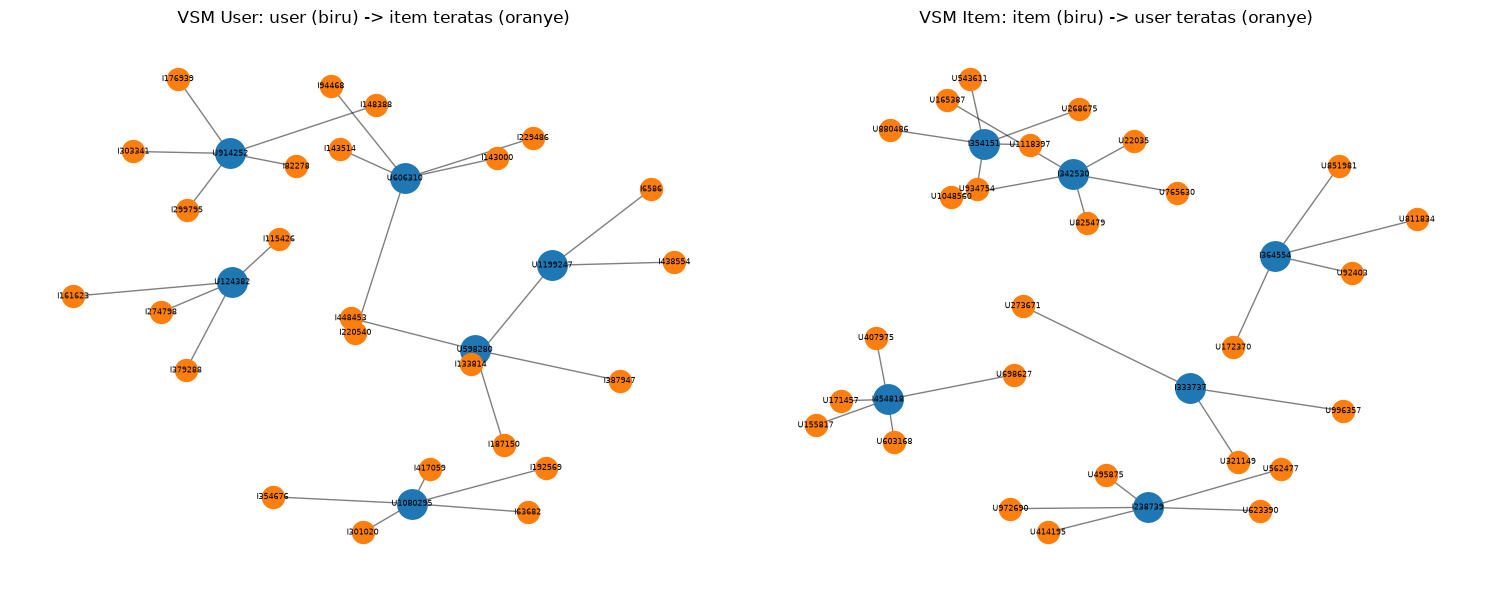

In [14]:
# Plot networkx: VSM User dan VSM Item
rng_plot = np.random.default_rng(SEED)

def plot_vsm_sample(M, ent_ids, oth_ids, ent_prefix, oth_prefix, title, n_ent=6, max_oth=5, ax=None):
    deg = np.diff(M.indptr)
    pool = np.where(deg >= 3)[0]
    pick = rng_plot.choice(pool, size=min(n_ent, len(pool)), replace=False)
    G = nx.Graph()
    for e in pick:
        row = M[e]
        top = row.indices[np.argsort(-row.data)[:max_oth]]
        for c in top:
            G.add_edge(f"{ent_prefix}{ent_ids[e]}", f"{oth_prefix}{oth_ids[c]}", weight=float(M[e, c]))
    ent_nodes = [n for n in G if n.startswith(ent_prefix)]
    oth_nodes = [n for n in G if n.startswith(oth_prefix)]
    pos = nx.spring_layout(G, seed=SEED, k=0.6)
    nx.draw_networkx_nodes(G, pos, nodelist=ent_nodes, node_color="tab:blue", node_size=450, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=oth_nodes, node_color="tab:orange", node_size=250, ax=ax)
    nx.draw_networkx_edges(G, pos, alpha=0.5, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
    ax.set_title(title)
    ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
plot_vsm_sample(X, uid, iid, "U", "I", "VSM User: user (biru) -> item teratas (oranye)", ax=axes[0])
plot_vsm_sample(XT, iid, uid, "I", "U", "VSM Item: item (biru) -> user teratas (oranye)", ax=axes[1])
plt.tight_layout()
plt.show()

In [ ]:
# Statistik derajat
deg_user = np.diff(X.indptr)
deg_item = np.diff(XT.indptr)
stat = pd.DataFrame({
    "user (item per user)": pd.Series(deg_user).describe(percentiles=[.5, .9, .99]),
    "item (user per item)": pd.Series(deg_item).describe(percentiles=[.5, .9, .99]),
})
display(stat.round(2))

,user (item per user),item (user per item)
count,161249.00,81034.00
mean,1.49,2.96
std,5.21,5.53
min,1.00,1.00
50%,1.00,1.00
90%,2.00,6.00
99%,7.00,24.00
max,874.00,257.00


### Proyeksi mana yang lebih baik (efektif/efisien)?

In [ ]:
# No. 6
B = (X > 0).astype(np.float32).tocsr()
n_u, n_i = B.shape
deg_u = np.asarray(B.sum(1)).ravel()
deg_i = np.asarray(B.sum(0)).ravel()
cost_user_proj = float((deg_i ** 2).sum())   
cost_item_proj = float((deg_u ** 2).sum())   

perbandingan = pd.DataFrame({
    "proyeksi": ["User-User (B·Bᵀ)", "Item-Item (Bᵀ·B)"],
    "dimensi": [f"{n_u} x {n_u}", f"{n_i} x {n_i}"],
    "ukuran dense (GB, float32)": [n_u ** 2 * 4 / 1e9, n_i ** 2 * 4 / 1e9],
    "batas atas pasangan non-nol": [cost_user_proj, cost_item_proj],
    "batas atas density": [min(1, cost_user_proj / n_u ** 2), min(1, cost_item_proj / n_i ** 2)],
}).set_index("proyeksi")
display(perbandingan)

FORCE = None
chosen = FORCE or ("item" if cost_item_proj <= cost_user_proj else "user")
print(f"==> Proyeksi yang dipilih: {chosen.upper()}-{chosen.upper()}")
print(
    f"Alasan: dimensi {'item' if chosen=='item' else 'user'} = {n_i if chosen=='item' else n_u:,} "
    f"vs {n_u if chosen=='item' else n_i:,}; estimasi pasangan non-nol "
    f"{min(cost_item_proj, cost_user_proj):,.0f} vs {max(cost_item_proj, cost_user_proj):,.0f}. "
    "Proyeksi dengan dimensi lebih kecil dan pasangan non-nol lebih sedikit lebih efisien (memori/komputasi) "
    "dan biasanya lebih stabil (tiap vektor punya lebih banyak data pendukung)."
)

,dimensi,"ukuran dense (GB, float32)",batas atas pasangan non-nol,batas atas density
proyeksi,,,,
User-User (B·Bᵀ),161249 x 161249,104.004960,3185732.0,0.000123
Item-Item (Bᵀ·B),81034 x 81034,26.266037,4734104.0,0.000721


==> Proyeksi yang dipilih: USER-USER
Alasan: dimensi user = 161,249 vs 81,034; estimasi pasangan non-nol 3,185,732 vs 4,734,104. Proyeksi dengan dimensi lebih kecil dan pasangan non-nol lebih sedikit lebih efisien (memori/komputasi) dan biasanya lebih stabil (tiap vektor punya lebih banyak data pendukung).


### Similarity pada graf terproyeksi

In [ ]:
# No. 7. persiapan
if chosen == "user":
    M, ent_ids, L, K = X, uid, "Visitor", "visitorId"
else:
    M, ent_ids, L, K = XT, iid, "Item", "itemId"

Mb = (M > 0).astype(np.float32).tocsr()
Mn = normalize(Mb, norm="l2")          
MnT = Mn.T.tocsr()

rng = np.random.default_rng(SEED)
kandidat = np.where(np.diff(Mb.indptr) >= 5)[0]
ref_idx = int(rng.choice(kandidat))
ref_id = int(ent_ids[ref_idx])
print(f"Record acuan: {L} {K}={ref_id} (derajat={int(Mb[ref_idx].nnz)})")

# snapshot kondisi SEBELUM similarity
sebelum = df_q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi")
display(sebelum)

Record acuan: Visitor visitorId=124914 (derajat=6)


,relasi,jumlah
0,ADDED_TO_CART,7985
1,BOUGHT,2712
2,VIEWED,299133


In [ ]:
# No. 7a. Cypher top-5 
REL_T = "VIEWED|ADDED_TO_CART|BOUGHT"
cypher_top5 = f"""
MATCH (a:{L} {{{K}: $ref}})-[:{REL_T}]-(x)-[:{REL_T}]-(b:{L})
WHERE a <> b
WITH a, b, count(DISTINCT x) AS common
MATCH (a)-[:{REL_T}]-(xa) WITH a, b, common, count(DISTINCT xa) AS da
MATCH (b)-[:{REL_T}]-(xb) WITH a, b, common, da, count(DISTINCT xb) AS db
RETURN b.{K} AS id, common, round(common / sqrt(da * db), 4) AS cosine
ORDER BY cosine DESC, common DESC
LIMIT 5
"""
print(cypher_top5)
top5_cypher = df_q(cypher_top5, ref=ref_id)
display(top5_cypher)


MATCH (a:Visitor {visitorId: $ref})-[:VIEWED|ADDED_TO_CART|BOUGHT]-(x)-[:VIEWED|ADDED_TO_CART|BOUGHT]-(b:Visitor)
WHERE a <> b
WITH a, b, count(DISTINCT x) AS common
MATCH (a)-[:VIEWED|ADDED_TO_CART|BOUGHT]-(xa) WITH a, b, common, count(DISTINCT xa) AS da
MATCH (b)-[:VIEWED|ADDED_TO_CART|BOUGHT]-(xb) WITH a, b, common, da, count(DISTINCT xb) AS db
RETURN b.visitorId AS id, common, round(common / sqrt(da * db), 4) AS cosine
ORDER BY cosine DESC, common DESC
LIMIT 5



,id,common,cosine
0,1245085,2,0.5774
1,608181,2,0.4714
2,579237,2,0.4714
3,165844,1,0.4082
4,1036049,1,0.4082


In [ ]:
# No. 7
sims = (Mn[ref_idx] @ MnT).toarray().ravel()
sims[ref_idx] = 0
top_idx = np.argsort(-sims)[:5]
top5_py = pd.DataFrame({"id": ent_ids[top_idx].astype(int), "cosine": sims[top_idx].round(4)})
print("Top-5 versi Python (harus konsisten dengan Cypher di atas):")
display(top5_py)

rows_write = [{"a": ref_id, "b": int(ent_ids[j]), "score": float(sims[j])} for j in top_idx if sims[j] > 0]
run("MATCH ()-[s:SIMILAR_TO]->() DELETE s") 
run(
    f"""
    UNWIND $rows AS r
    MATCH (a:{L} {{{K}: r.a}}), (b:{L} {{{K}: r.b}})
    MERGE (a)-[s:SIMILAR_TO]->(b)
    SET s.score = r.score, s.metric = 'cosine_binary'
    """,
    rows=rows_write,
)

query_baca = f"""
MATCH (a:{L} {{{K}: $ref}})-[s:SIMILAR_TO]->(b:{L})
RETURN a.{K} AS acuan, b.{K} AS mirip, s.score AS score
ORDER BY score DESC
"""
print(query_baca)
display(df_q(query_baca, ref=ref_id))

Top-5 versi Python (harus konsisten dengan Cypher di atas):


,id,cosine
0,1245085,0.5774
1,579237,0.4714
2,608181,0.4714
3,1383132,0.4082
4,1272831,0.4082



MATCH (a:Visitor {visitorId: $ref})-[s:SIMILAR_TO]->(b:Visitor)
RETURN a.visitorId AS acuan, b.visitorId AS mirip, s.score AS score
ORDER BY score DESC



,acuan,mirip,score
0,124914,1245085,0.577350
1,124914,579237,0.471405
2,124914,608181,0.471405
3,124914,1272831,0.408248
4,124914,1383132,0.408248


### Kondisi graf sebelum dan sesudah perhitungan similarity

,relasi,jumlah_sebelum,jumlah_sesudah
0,ADDED_TO_CART,7985.0,7985
1,BOUGHT,2712.0,2712
2,SIMILAR_TO,0.0,5
3,VIEWED,299133.0,299133


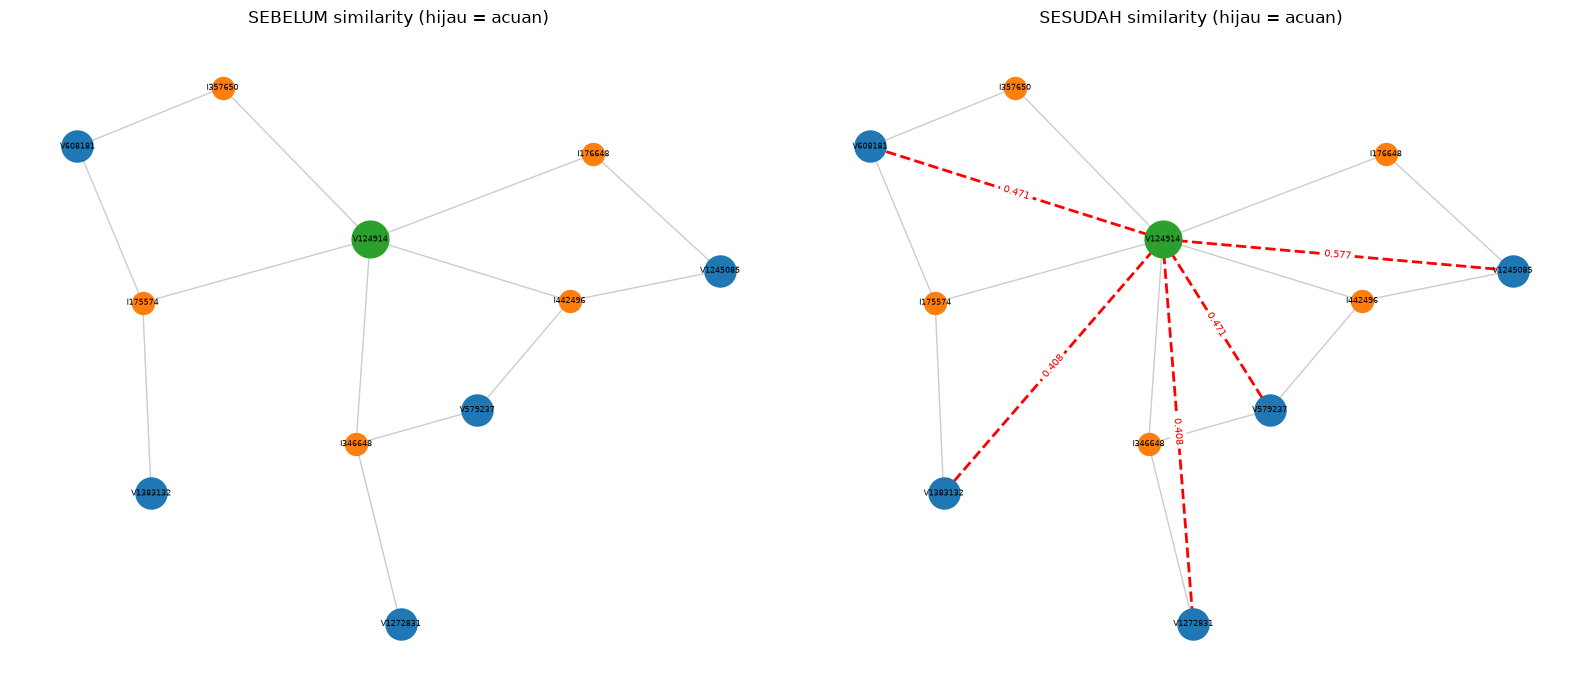

In [20]:
# No. 8
sesudah = df_q("MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah ORDER BY relasi")
cmp_rel = sebelum.merge(sesudah, on="relasi", how="outer", suffixes=("_sebelum", "_sesudah")).fillna(0)
display(cmp_rel)

def ego_graph(with_similar, max_oth=8):
    nodes = [ref_idx] + [int(j) for j in top_idx if sims[j] > 0]
    ref_cols = set(Mb[ref_idx].indices)
    cnt = {}
    for e in nodes[1:]:
        for c in set(Mb[e].indices) & ref_cols:
            cnt[c] = cnt.get(c, 0) + 1
    others = [c for c, _ in sorted(cnt.items(), key=lambda t: -t[1])[:max_oth]]
    if not others:
        others = list(ref_cols)[:max_oth]
    pre_e, pre_o = L[0], ("I" if L == "Visitor" else "V")
    G = nx.Graph()
    for e in nodes:
        G.add_node(f"{pre_e}{int(ent_ids[e])}")
        cols = set(Mb[e].indices)
        for c in others:
            if c in cols:
                oth_id = int(iid[c]) if L == "Visitor" else int(uid[c])
                G.add_edge(f"{pre_e}{int(ent_ids[e])}", f"{pre_o}{oth_id}", kind="interaksi")
    sim_edges = []
    if with_similar:
        for j in top_idx:
            if sims[j] > 0:
                sim_edges.append((f"{pre_e}{ref_id}", f"{pre_e}{int(ent_ids[j])}", round(float(sims[j]), 3)))
    return G, sim_edges, pre_e

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, flag, judul in [(axes[0], False, "SEBELUM similarity"), (axes[1], True, "SESUDAH similarity")]:
    G, sim_edges, pre_e = ego_graph(flag)
    for a, b, _ in sim_edges:
        G.add_node(a); G.add_node(b)
    pos = nx.spring_layout(G, seed=SEED, k=0.9)
    ent_nodes = [n for n in G if n.startswith(pre_e)]
    oth_nodes = [n for n in G if not n.startswith(pre_e)]
    nx.draw_networkx_nodes(G, pos, nodelist=ent_nodes, node_color="tab:blue", node_size=500, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[f"{pre_e}{ref_id}"], node_color="tab:green", node_size=700, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=oth_nodes, node_color="tab:orange", node_size=250, ax=ax)
    nx.draw_networkx_edges(G, pos, alpha=0.4, edge_color="gray", ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=6, ax=ax)
    if sim_edges:
        nx.draw_networkx_edges(G, pos, edgelist=[(a, b) for a, b, _ in sim_edges], edge_color="red",
                               style="dashed", width=2, ax=ax)
        nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): s for a, b, s in sim_edges},
                                     font_color="red", font_size=7, ax=ax)
    ax.set_title(f"{judul} (hijau = acuan)")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Analytics
### Rekomendasi user-based KNN (k = 5)

In [ ]:
# No. 1a
K_NN = 5
N_ADS = 3
Xn = normalize(X, norm="l2")
XnT = Xn.T.tocsr()

def recommend_knn(user_id, k=K_NN, n_rec=5):
    ui = uid_index.get_loc(user_id)
    sim = (Xn[ui] @ XnT).toarray().ravel()
    sim[ui] = 0.0
    nn = np.argpartition(-sim, k)[:k]
    nn = nn[np.argsort(-sim[nn])]
    nn = nn[sim[nn] > 0]
    if len(nn) == 0:
        return nn, sim, []
    skor = (sp.csr_matrix(sim[nn].reshape(1, -1)) @ X[nn]).toarray().ravel()
    skor[X[ui].indices] = 0.0                      
    top = np.argsort(-skor)[:n_rec]
    top = top[skor[top] > 0]
    return nn, sim, [(int(iid[j]), float(skor[j])) for j in top]

GT_EVENTS = ["view", "addtocart", "transaction"]
test = pd.read_csv(P2_CSV)
test = test[test["event"].isin(GT_EVENTS)]
gt = test.groupby("visitorid")["itemid"].apply(set).to_dict()

kandidat_user = sorted(u for u in gt if u in uid_index)
print("Kandidat user (ada di P1 dan P2):", len(kandidat_user))

rng_user = np.random.default_rng(SEED)
urutan = rng_user.permutation(kandidat_user)
target, hasil = None, None
for u in urutan[:500]:
    u = int(u)
    nn, sim, recs = recommend_knn(u)
    if len(recs) >= N_ADS:
        target, hasil = u, (nn, sim, recs)
        break
assert target is not None, "Tidak ada user valid; coba ganti SEED atau periode."
nn, sim, recs = hasil
print(f"User terpilih (SEED={SEED}): visitorid = {target}")
print("Jumlah item di training:", int(X[uid_index.get_loc(target)].nnz))

Kandidat user (ada di P1 dan P2): 2307
User terpilih (SEED=42): visitorid = 21682
Jumlah item di training: 2


In [ ]:
# No. 1b. 3 item iklan untuk k=5
tabel_nn = pd.DataFrame({"visitorid": uid[nn].astype(int), "cosine": sim[nn].round(4)})
print(f"{K_NN} tetangga terdekat (KNN):")
display(tabel_nn)

tabel_rec = pd.DataFrame(recs, columns=["itemid", "skor"])
tabel_rec.index = np.arange(1, len(tabel_rec) + 1)
tabel_rec.index.name = "rank"
print("Kandidat rekomendasi (top-5), 3 teratas = item yang diiklankan:")
display(tabel_rec)
iklan = tabel_rec["itemid"].head(N_ADS).tolist()
print("Item yang diiklankan:", iklan)

5 tetangga terdekat (KNN):


,visitorid,cosine
0,758601,0.7071
1,1021667,0.6325
2,10053,0.5000
3,1394234,0.4082


Kandidat rekomendasi (top-5), 3 teratas = item yang diiklankan:


,itemid,skor
rank,,
1,230397,0.632456
2,180434,0.500000
3,245873,0.408248
4,453177,0.408248


Item yang diiklankan: [230397, 180434, 245873]


Query untuk Neo4j Browser (visual): MATCH p=(u:Visitor {visitorId: 21682})-[:KNN_NEIGHBOR|RECOMMENDED]->() RETURN p


,item,rank,skor,iklan
0,230397,1,0.632456,True
1,180434,2,0.500000,True
2,245873,3,0.408248,True
3,453177,4,0.408248,False


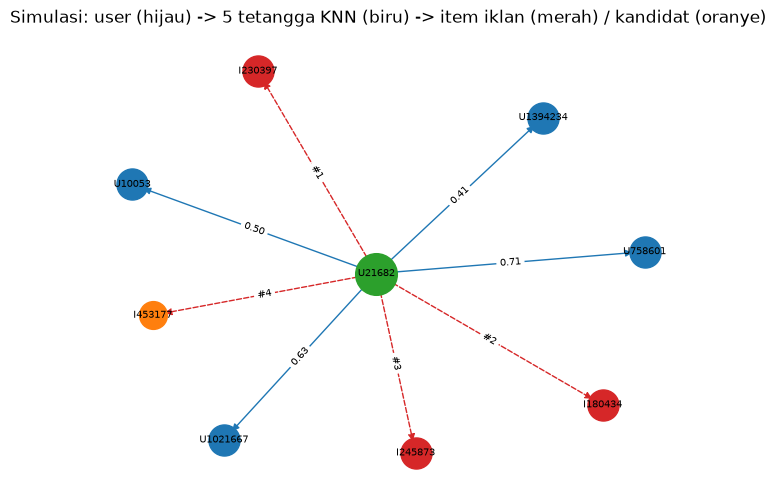

SIMULASI IKLAN: pengunjung 21682 akan melihat iklan item [230397, 180434, 245873]


In [ ]:
# No. 1b
run("MATCH ()-[r:KNN_NEIGHBOR|RECOMMENDED]->() DELETE r")
run(
    """
    MATCH (u:Visitor {visitorId: $u})
    UNWIND $nbrs AS n
    MATCH (v:Visitor {visitorId: n.id})
    MERGE (u)-[s:KNN_NEIGHBOR]->(v) SET s.cosine = n.cosine, s.k = $k
    """,
    u=target, k=K_NN, nbrs=[{"id": int(a), "cosine": float(b)} for a, b in zip(uid[nn], sim[nn])],
)
run(
    """
    MATCH (u:Visitor {visitorId: $u})
    UNWIND $items AS it
    MATCH (i:Item {itemId: it.id})
    MERGE (u)-[r:RECOMMENDED]->(i) SET r.rank = it.rank, r.score = it.score, r.iklan = (it.rank <= $ads)
    """,
    u=target, ads=N_ADS,
    items=[{"id": int(i), "rank": r, "score": float(s)} for r, (i, s) in enumerate(recs, 1)],
)

q_sim = """
MATCH (u:Visitor {visitorId: $u})-[r:RECOMMENDED]->(i:Item)
RETURN i.itemId AS item, r.rank AS rank, r.score AS skor, r.iklan AS iklan ORDER BY rank
"""
print("Query untuk Neo4j Browser (visual): MATCH p=(u:Visitor {visitorId: %d})-[:KNN_NEIGHBOR|RECOMMENDED]->() RETURN p" % target)
display(df_q(q_sim, u=target))

Gs = nx.DiGraph()
tu = f"U{target}"
for a, b in zip(uid[nn], sim[nn]):
    Gs.add_edge(tu, f"U{int(a)}", kind="knn", label=f"{b:.2f}")
for r, (i, s) in enumerate(recs, 1):
    Gs.add_edge(tu, f"I{i}", kind="rec", label=f"#{r}")
pos = nx.spring_layout(Gs, seed=SEED, k=1.2)
plt.figure(figsize=(8, 6))
nx.draw_networkx_nodes(Gs, pos, nodelist=[tu], node_color="tab:green", node_size=900)
nx.draw_networkx_nodes(Gs, pos, nodelist=[f"U{int(a)}" for a in uid[nn]], node_color="tab:blue", node_size=500)
nx.draw_networkx_nodes(Gs, pos, nodelist=[f"I{i}" for i, _ in recs[:N_ADS]], node_color="tab:red", node_size=500)
nx.draw_networkx_nodes(Gs, pos, nodelist=[f"I{i}" for i, _ in recs[N_ADS:]], node_color="tab:orange", node_size=400)
nx.draw_networkx_edges(Gs, pos, edgelist=[e for e in Gs.edges if Gs.edges[e]["kind"] == "knn"], edge_color="tab:blue")
nx.draw_networkx_edges(Gs, pos, edgelist=[e for e in Gs.edges if Gs.edges[e]["kind"] == "rec"], edge_color="tab:red", style="dashed")
nx.draw_networkx_labels(Gs, pos, font_size=7)
nx.draw_networkx_edge_labels(Gs, pos, edge_labels={e: Gs.edges[e]["label"] for e in Gs.edges}, font_size=7)
plt.title("Simulasi: user (hijau) -> 5 tetangga KNN (biru) -> item iklan (merah) / kandidat (oranye)")
plt.axis("off"); plt.show()

print(f"SIMULASI IKLAN: pengunjung {target} akan melihat iklan item {iklan}")

### Evaluasi Hit@5 dan NDCG@5

In [24]:
# No. 2
def hit_at_k(rec_items, rel, k):
    return int(any(i in rel for i in rec_items[:k]))

def ndcg_at_k(rec_items, rel, k):
    dcg = sum(1.0 / math.log2(r + 2) for r, i in enumerate(rec_items[:k]) if i in rel)
    idcg = sum(1.0 / math.log2(r + 2) for r in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

rel = gt[target]
rec_items = tabel_rec["itemid"].tolist()
print(f"Item relevan di P2 untuk user {target}: {len(rel)} item")
print("Irisan dengan rekomendasi:", [i for i in rec_items if i in rel])

hasil_eval = pd.DataFrame({
    "metrik": ["Hit@5", "NDCG@5", "Hit@3 (iklan)", "NDCG@3 (iklan)"],
    "nilai": [hit_at_k(rec_items, rel, 5), round(ndcg_at_k(rec_items, rel, 5), 4),
              hit_at_k(rec_items, rel, 3), round(ndcg_at_k(rec_items, rel, 3), 4)],
})
display(hasil_eval)

Item relevan di P2 untuk user 21682: 2 item
Irisan dengan rekomendasi: []


,metrik,nilai
0,Hit@5,0.0
1,NDCG@5,0.0
2,Hit@3 (iklan),0.0
3,NDCG@3 (iklan),0.0


### Evaluasi agregat pada banyak user
Hasil satu user hanya bernilai 0/1 untuk Hit@5, sehingga kurang representatif.

In [ ]:
N_EVAL = 200
rng_eval = np.random.default_rng(SEED + 1)
sampel = rng_eval.permutation(kandidat_user)[:N_EVAL]
hits, ndcgs, n_ok = [], [], 0
for u in tqdm(sampel, desc="Evaluasi agregat"):
    _, _, r = recommend_knn(int(u))
    if not r:
        continue
    items = [x for x, _ in r]
    n_ok += 1
    hits.append(hit_at_k(items, gt[int(u)], 5))
    ndcgs.append(ndcg_at_k(items, gt[int(u)], 5))
print(f"User dievaluasi: {n_ok}/{len(sampel)} (sisanya tidak punya tetangga/rekomendasi)")
print(f"Rata-rata Hit@5  : {np.mean(hits):.4f}")
print(f"Rata-rata NDCG@5 : {np.mean(ndcgs):.4f}")

Evaluasi agregat: 100%|██████████| 200/200 [00:00<00:00, 387.16it/s]

User dievaluasi: 77/200 (sisanya tidak punya tetangga/rekomendasi)
Rata-rata Hit@5  : 0.0000
Rata-rata NDCG@5 : 0.0000


In [ ]:
# Tutup koneksi
reset_driver()